In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
  accuracy_score,
  precision_score,
  recall_score,
  f1_score,
  confusion_matrix,
ConfusionMatrixDisplay
)

In [3]:
# loading data

results = pd.read_csv("data/prediction_results.csv")

print(results.head())

   actual classes  linear svc predictions  poly svc predictions  \
0               1                       1                     1   
1               1                       0                     1   
2               1                       1                     1   
3               1                       1                     1   
4               0                       0                     1   

   rbf svc predictions  correct linear predictions  correct poly predictions  \
0                    1                        True                      True   
1                    1                       False                      True   
2                    1                        True                      True   
3                    1                        True                      True   
4                    0                        True                     False   

   correct rbf predictions  
0                     True  
1                     True  
2                     True  


In [7]:
# calculating accuracy, presision, recall, and F1_score

y_test = results["actual classes"]
predictions = {
    "linear": results["linear svc predictions"],
    "polynomial": results["poly svc predictions"],
    "rbf": results["rbf svc predictions"]
}

evaluations = {}

for name, y_pred in (predictions.items()):
    evaluations[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),   # class 1 is considered to be the positive calss
        "Recall": recall_score(y_test, y_pred, pos_label=1),
        "F1-score": f1_score(y_test, y_pred, pos_label=1)
    }
    
metrics_df = pd.DataFrame(evaluations).T

print(metrics_df.round(4))

            Accuracy  Precision  Recall  F1-score
linear        0.6133     0.5752  0.8667    0.6915
polynomial    0.5533     0.5282  1.0000    0.6912
rbf           0.9933     0.9933  0.9933    0.9933


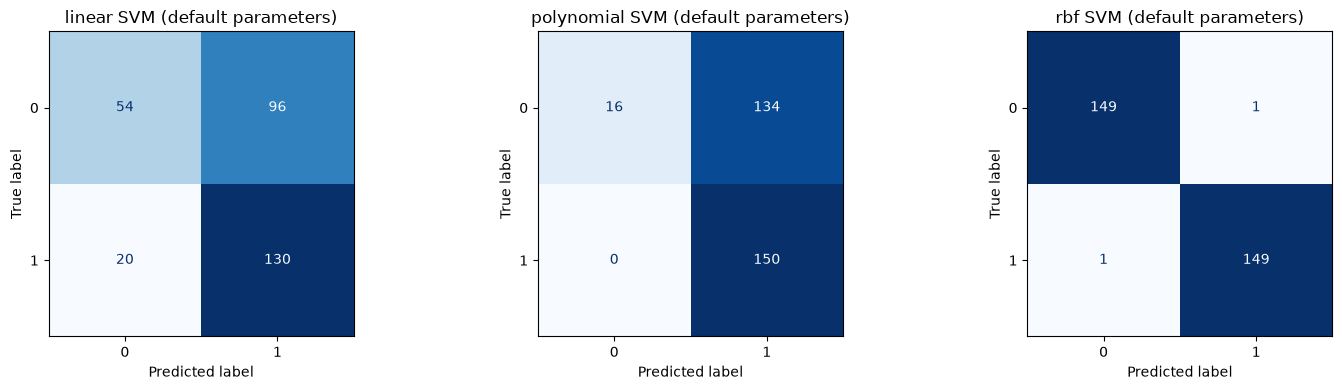

In [12]:
# CONFUSION MATRIX

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(f"{name} SVM (default parameters)")

plt.tight_layout()
plt.show()



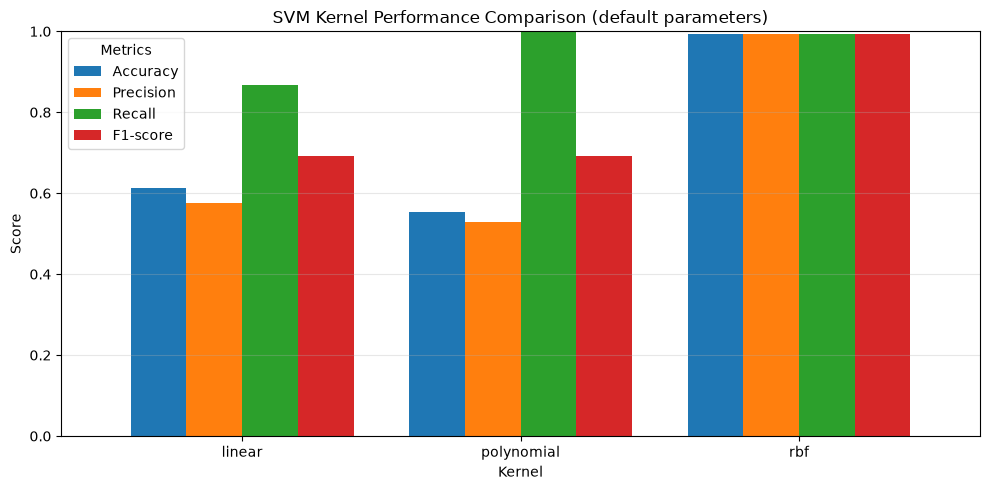

In [13]:
# comparing models

metrics_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    width=0.8
)

plt.title("SVM Kernel Performance Comparison (default parameters)")
plt.xlabel("Kernel")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()